# Breast Cancer Classification: SVM vs Random Forest vs AdaBoost
## 1. Aim and Imports

**Aim:** Implement and compare three classifiers on the Breast Cancer (Wisconsin Diagnostic) dataset:
- Support Vector Machine (SVM)
- Random Forest
- AdaBoost

**Tasks:** 5-fold stratified cross-validation, hyperparameter tuning with Grid Search, and a before vs. after optimization comparison.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

sns.set_style("whitegrid")
RANDOM_STATE = 42
print("Libraries imported successfully")

Libraries imported successfully


## 2. Dataset Loading and Exploration

In [2]:
# Upload breast_cancer_dataset.csv when prompted (skipped if the file is already in the Colab session)
import os
if not os.path.exists("breast_cancer_dataset.csv"):
    from google.colab import files
    uploaded = files.upload()

df = pd.read_csv("breast_cancer_dataset.csv")
print("Raw shape:", df.shape)

Raw shape: (569, 33)


In [3]:
# The CSV has a trailing comma on every row, which creates an empty 'Unnamed: 32' column. Drop it.
df = df.dropna(axis=1, how="all")
print("Shape after removing empty columns:", df.shape)

print("\nFirst five rows:")
display(df.head())

Shape after removing empty columns: (569, 32)

First five rows:


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


Shape (rows, columns): (569, 32)

Missing values per column (non-zero only):
No missing values

Class distribution:
diagnosis
B    357
M    212
Name: count, dtype: int64
diagnosis
B    62.74 %
M    37.26 %
Name: proportion, dtype: object


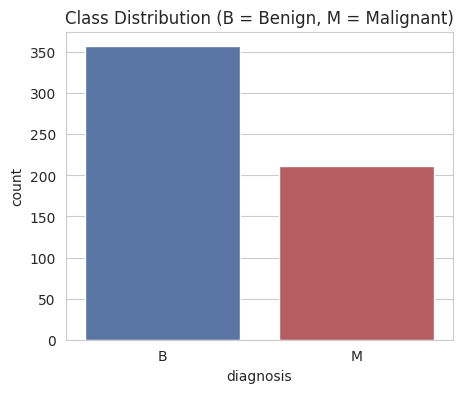


Basic statistics:


,count,mean,std,min,25%,50%,75%,max
id,569.0,3.037183e+07,1.250206e+08,8670.000000,869218.000000,906024.000000,8.813129e+06,9.113205e+08
radius_mean,569.0,1.412729e+01,3.524049e+00,6.981000,11.700000,13.370000,1.578000e+01,2.811000e+01
texture_mean,569.0,1.928965e+01,4.301036e+00,9.710000,16.170000,18.840000,2.180000e+01,3.928000e+01
perimeter_mean,569.0,9.196903e+01,2.429898e+01,43.790000,75.170000,86.240000,1.041000e+02,1.885000e+02
area_mean,569.0,6.548891e+02,3.519141e+02,143.500000,420.300000,551.100000,7.827000e+02,2.501000e+03
smoothness_mean,569.0,9.636028e-02,1.406413e-02,0.052630,0.086370,0.095870,1.053000e-01,1.634000e-01
compactness_mean,569.0,1.043410e-01,5.281276e-02,0.019380,0.064920,0.092630,1.304000e-01,3.454000e-01
concavity_mean,569.0,8.879932e-02,7.971981e-02,0.000000,0.029560,0.061540,1.307000e-01,4.268000e-01
concave points_mean,569.0,4.891915e-02,3.880284e-02,0.000000,0.020310,0.033500,7.400000e-02,2.012000e-01
symmetry_mean,569.0,1.811619e-01,2.741428e-02,0.106000,0.161900,0.179200,1.957000e-01,3.040000e-01


In [4]:
print("Shape (rows, columns):", df.shape)

print("\nMissing values per column (non-zero only):")
missing = df.isnull().sum()
print(missing[missing > 0] if missing.sum() > 0 else "No missing values")

print("\nClass distribution:")
counts = df["diagnosis"].value_counts()
print(counts)
print((df["diagnosis"].value_counts(normalize=True) * 100).round(2).astype(str) + " %")

plt.figure(figsize=(5, 4))
sns.countplot(x="diagnosis", data=df, palette=["#4C72B0", "#C44E52"], order=["B", "M"])
plt.title("Class Distribution (B = Benign, M = Malignant)")
plt.show()

print("\nBasic statistics:")
display(df.describe().T)

## 3. Preprocessing and Data Splitting
- `id` is only an identifier, so it is dropped.
- `diagnosis` is the target: **M (malignant) = 1**, **B (benign) = 0**.
- 80:20 **stratified** train-test split keeps the class ratio identical in both sets.

In [5]:
X = df.drop(columns=["id", "diagnosis"])
y = df["diagnosis"].map({"B": 0, "M": 1})

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Train class ratio (malignant):", round(y_train.mean(), 3))
print("Test class ratio (malignant): ", round(y_test.mean(), 3))

Train: (455, 30) | Test: (114, 30)
Train class ratio (malignant): 0.374
Test class ratio (malignant):  0.368


## 4. Baseline Model Training and Evaluation
All models use **default parameters**. SVM is sensitive to feature scale, so it is wrapped in a `Pipeline` with `StandardScaler`.
The scaler is fitted only on training data (inside each CV fold as well), so there is no data leakage. Tree-based models do not need scaling.

In [6]:
baseline_models = {
    "SVM": Pipeline([("scaler", StandardScaler()), ("svc", SVC(random_state=RANDOM_STATE))]),
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE),
    "AdaBoost": AdaBoostClassifier(random_state=RANDOM_STATE),
}

def evaluate(model, X_te, y_te):
    pred = model.predict(X_te)
    return {
        "Accuracy": accuracy_score(y_te, pred),
        "Precision": precision_score(y_te, pred),
        "Recall": recall_score(y_te, pred),
        "F1-Score": f1_score(y_te, pred),
    }

baseline_results = {}
for name, model in baseline_models.items():
    model.fit(X_train, y_train)
    baseline_results[name] = evaluate(model, X_test, y_test)

baseline_df = pd.DataFrame(baseline_results).T
print("Baseline performance on the test set (default parameters):")
display(baseline_df.round(4))

Baseline performance on the test set (default parameters):


,Accuracy,Precision,Recall,F1-Score
SVM,0.9737,1.0,0.9286,0.9630
Random Forest,0.9737,1.0,0.9286,0.9630
AdaBoost,0.9825,1.0,0.9524,0.9756


## 5. Cross-Validation
5-fold stratified cross-validation on the training set to compare the baseline models.

,Fold scores,Mean Accuracy,Std Dev
Model,,,
SVM,"[0.967, 0.978, 0.967, 0.967, 0.978]",0.9714,0.0054
Random Forest,"[0.956, 0.989, 0.9451, 0.967, 0.967]",0.9648,0.0146
AdaBoost,"[0.9451, 0.978, 0.956, 0.967, 0.989]",0.9670,0.0155


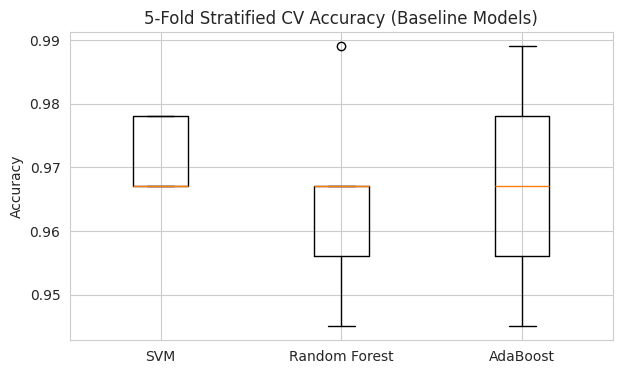

In [7]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_rows, cv_scores_store = [], {}
for name, model in baseline_models.items():
    scores = cross_val_score(model, X_train, y_train, cv=skf, scoring="accuracy")
    cv_scores_store[name] = scores
    cv_rows.append({"Model": name, "Fold scores": np.round(scores, 4),
                    "Mean Accuracy": scores.mean(), "Std Dev": scores.std()})

cv_df = pd.DataFrame(cv_rows).set_index("Model")
display(cv_df.round(4))

plt.figure(figsize=(7, 4))
plt.boxplot(cv_scores_store.values(), labels=cv_scores_store.keys())
plt.ylabel("Accuracy")
plt.title("5-Fold Stratified CV Accuracy (Baseline Models)")
plt.show()

## 6. Hyperparameter Tuning using Grid Search
`GridSearchCV` with 5-fold stratified CV, optimizing **F1-score** (a balanced metric for this medical task).

In [8]:
param_grids = {
    "SVM": {
        "svc__C": [0.1, 1, 10, 100],
        "svc__gamma": ["scale", 0.001, 0.01, 0.1],
        "svc__kernel": ["rbf", "linear"],
    },
    "Random Forest": {
        "n_estimators": [100, 200, 300],
        "max_depth": [None, 5, 10, 20],
        "min_samples_split": [2, 5, 10],
        "min_samples_leaf": [1, 2, 4],
    },
    "AdaBoost": {
        "n_estimators": [50, 100, 200, 300],
        "learning_rate": [0.01, 0.1, 0.5, 1.0],
    },
}

grid_models = {
    "SVM": Pipeline([("scaler", StandardScaler()), ("svc", SVC(random_state=RANDOM_STATE))]),
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE),
    "AdaBoost": AdaBoostClassifier(random_state=RANDOM_STATE),
}

best_models, grid_rows = {}, []
for name in grid_models:
    print(f"Tuning {name} ...")
    gs = GridSearchCV(grid_models[name], param_grids[name], cv=skf, scoring="f1", n_jobs=-1)
    gs.fit(X_train, y_train)
    best_models[name] = gs.best_estimator_

    best_idx = gs.best_index_
    print("  Best parameters :", gs.best_params_)
    print(f"  Best CV F1-score: {gs.best_score_:.4f}\n")

    # CV accuracy of the tuned model for a like-for-like comparison with Section 5
    tuned_acc = cross_val_score(gs.best_estimator_, X_train, y_train, cv=skf, scoring="accuracy")
    grid_rows.append({"Model": name, "Best Parameters": gs.best_params_,
                      "Best CV F1": gs.best_score_, "CV Accuracy (tuned)": tuned_acc.mean(),
                      "CV Accuracy (baseline)": cv_scores_store[name].mean()})

grid_df = pd.DataFrame(grid_rows).set_index("Model")
pd.set_option("display.max_colwidth", None)
display(grid_df)

Tuning SVM ...
  Best parameters : {'svc__C': 10, 'svc__gamma': 'scale', 'svc__kernel': 'rbf'}
  Best CV F1-score: 0.9674

Tuning Random Forest ...
  Best parameters : {'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}
  Best CV F1-score: 0.9553

Tuning AdaBoost ...
  Best parameters : {'learning_rate': 1.0, 'n_estimators': 300}
  Best CV F1-score: 0.9671



,Best Parameters,Best CV F1,CV Accuracy (tuned),CV Accuracy (baseline)
Model,,,,
SVM,"{'svc__C': 10, 'svc__gamma': 'scale', 'svc__kernel': 'rbf'}",0.967410,0.975824,0.971429
Random Forest,"{'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}",0.955285,0.967033,0.964835
AdaBoost,"{'learning_rate': 1.0, 'n_estimators': 300}",0.967068,0.975824,0.967033


## 7. Optimized Model Evaluation and Comparison

In [9]:
tuned_results = {name: evaluate(model, X_test, y_test) for name, model in best_models.items()}
tuned_df = pd.DataFrame(tuned_results).T
print("Tuned model performance on the test set:")
display(tuned_df.round(4))

# Before vs After table
comparison = pd.concat({"Before (Default)": baseline_df, "After (Tuned)": tuned_df}, axis=1)
comparison = comparison.swaplevel(axis=1).sort_index(axis=1, level=0, sort_remaining=False)
print("\nBefore vs After optimization:")
display(comparison.round(4))

change = (tuned_df - baseline_df).round(4)
print("Change (After - Before):")
display(change)

Tuned model performance on the test set:


,Accuracy,Precision,Recall,F1-Score
SVM,0.9737,1.0,0.9286,0.963
Random Forest,0.9737,1.0,0.9286,0.963
AdaBoost,0.9737,1.0,0.9286,0.963



Before vs After optimization:


Accuracy                       F1-Score                \
              Before (Default) After (Tuned) Before (Default) After (Tuned)   
SVM                     0.9737        0.9737           0.9630         0.963   
Random Forest           0.9737        0.9737           0.9630         0.963   
AdaBoost                0.9825        0.9737           0.9756         0.963   

                     Precision                         Recall                
              Before (Default) After (Tuned) Before (Default) After (Tuned)  
SVM                        1.0           1.0           0.9286        0.9286  
Random Forest              1.0           1.0           0.9286        0.9286  
AdaBoost                   1.0           1.0           0.9524        0.9286

Change (After - Before):


,Accuracy,Precision,Recall,F1-Score
SVM,0.0000,0.0,0.0000,0.0000
Random Forest,0.0000,0.0,0.0000,0.0000
AdaBoost,-0.0088,0.0,-0.0238,-0.0126


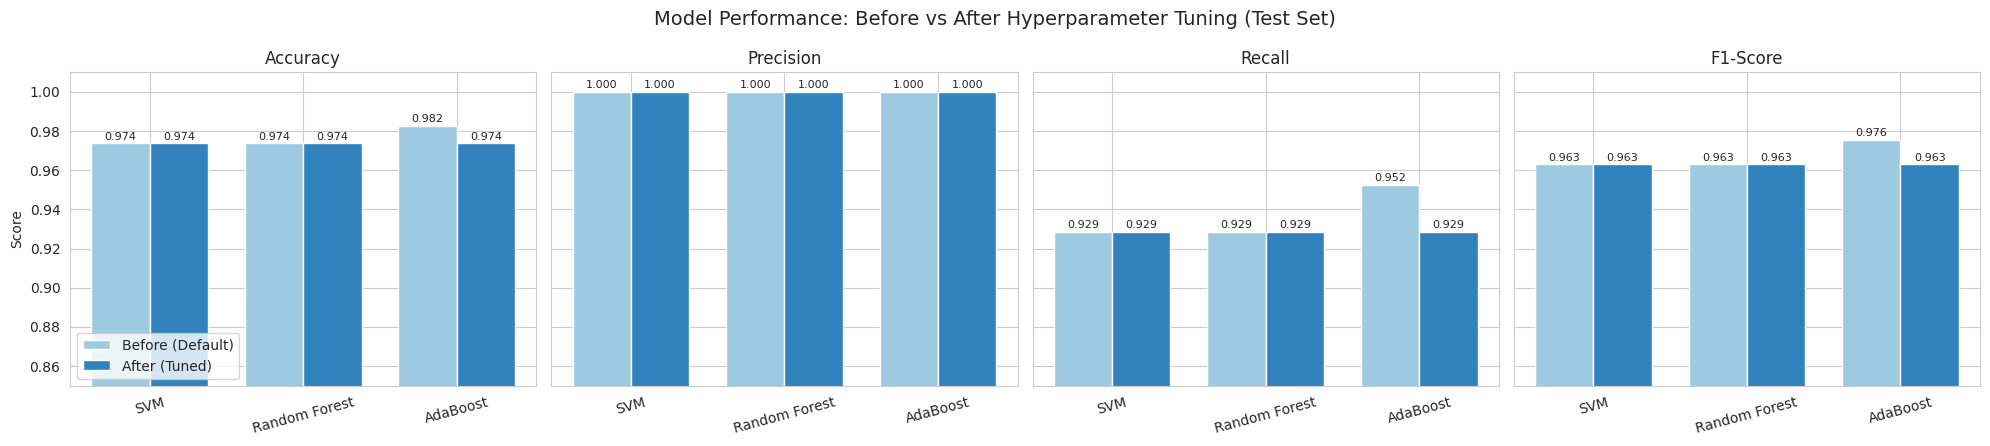

In [10]:
# Bar chart: before vs after for every metric
metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]
models = list(baseline_df.index)
x = np.arange(len(models)); w = 0.38

fig, axes = plt.subplots(1, 4, figsize=(20, 4.5), sharey=True)
for ax, m in zip(axes, metrics):
    b = ax.bar(x - w/2, baseline_df[m], w, label="Before (Default)", color="#9ecae1")
    a = ax.bar(x + w/2, tuned_df[m], w, label="After (Tuned)", color="#3182bd")
    ax.set_title(m); ax.set_xticks(x); ax.set_xticklabels(models, rotation=15)
    ax.set_ylim(0.85, 1.01)
    for bars in (b, a):
        for r in bars:
            ax.text(r.get_x() + r.get_width()/2, r.get_height() + 0.002, f"{r.get_height():.3f}",
                    ha="center", fontsize=8)
axes[0].set_ylabel("Score"); axes[0].legend(loc="lower left")
plt.suptitle("Model Performance: Before vs After Hyperparameter Tuning (Test Set)", fontsize=14)
plt.tight_layout(); plt.show()

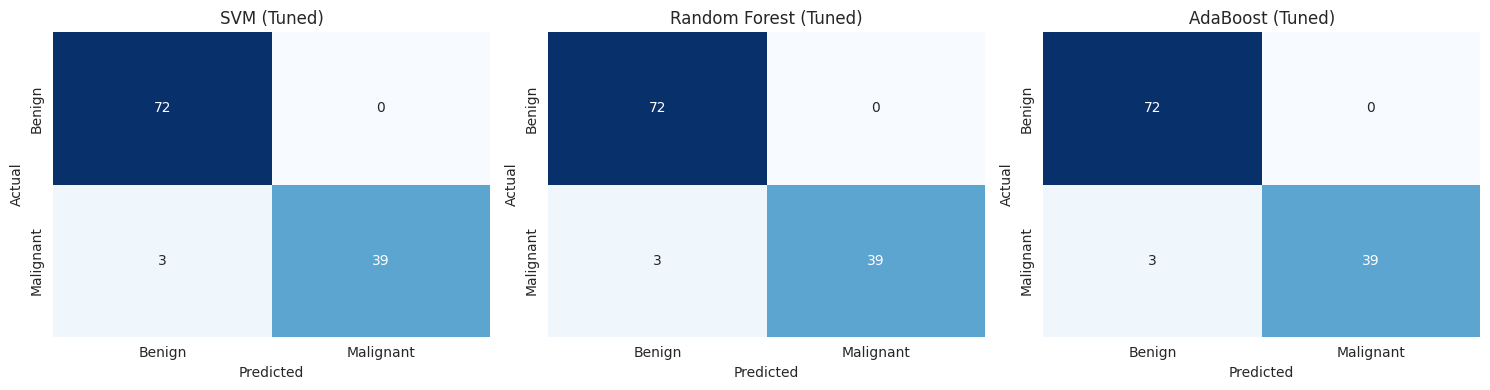

In [11]:
# Confusion matrices of the tuned models
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, model) in zip(axes, best_models.items()):
    cm = confusion_matrix(y_test, model.predict(X_test))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Benign", "Malignant"], yticklabels=["Benign", "Malignant"])
    ax.set_title(f"{name} (Tuned)"); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.show()

## 8. Results and Conclusion

In [12]:
def top(series):
    best = series.max()
    return ", ".join(series[series == best].index) + f" ({best:.4f})"

f1_change = tuned_df["F1-Score"] - baseline_df["F1-Score"]
cv_gain = grid_df["CV Accuracy (tuned)"].astype(float) - grid_df["CV Accuracy (baseline)"].astype(float)

print("ANALYSIS")
print("-" * 70)
print("1. Best test F1 before tuning :", top(baseline_df["F1-Score"]))
print("2. Best test F1 after tuning  :", top(tuned_df["F1-Score"]))
print("3. Test F1 change after tuning:", f1_change.round(4).to_dict())
print("4. CV accuracy change         :", cv_gain.round(4).to_dict())
print("5. Highest recall after tuning:", top(tuned_df["Recall"]))
print("6. Most stable in CV (std)    :", cv_df["Std Dev"].astype(float).idxmin())
print("-" * 70)

cv_compare = grid_df[["CV Accuracy (baseline)", "CV Accuracy (tuned)"]].astype(float).round(4)
print("Cross-validation accuracy, before vs after tuning:")
display(cv_compare)

ANALYSIS
----------------------------------------------------------------------
1. Best test F1 before tuning : AdaBoost (0.9756)
2. Best test F1 after tuning  : SVM, Random Forest, AdaBoost (0.9630)
3. Test F1 change after tuning: {'SVM': 0.0, 'Random Forest': 0.0, 'AdaBoost': -0.0126}
4. CV accuracy change         : {'SVM': 0.0044, 'Random Forest': 0.0022, 'AdaBoost': 0.0088}
5. Highest recall after tuning: SVM, Random Forest, AdaBoost (0.9286)
6. Most stable in CV (std)    : SVM
----------------------------------------------------------------------
Cross-validation accuracy, before vs after tuning:


,CV Accuracy (baseline),CV Accuracy (tuned)
Model,,
SVM,0.9714,0.9758
Random Forest,0.9648,0.9670
AdaBoost,0.9670,0.9758
